In [42]:
#1.导入库
#2.读取数据
#3.数据查看
#4.数据清洗
#5.数据特征构造
#6.数据分析
#7.数据可视化

In [95]:
#1.导入库 seaborn是包含在matplotlib库中的二次封装库，用于统计绘图
import numpy as np
import pandas as pd
import seaborn as sns #可视化库seaborn:基于matplotlib的高级绘图库，提供了更高级的接口，可以直接生成更复杂的统计图表(箱线图、热力图等)
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['font.sans-serif'] = ['SimHei']

In [53]:
#2.读取数据
df=pd.read_csv('data/house_sales.csv')

In [54]:
#3.数据查看(查看数据基本信息)
print(len(df)) #查看数据条数
print(len(df.columns)) #查看数据前5条
print(df.info()) #查看数据基本信息
print() #查看数据统计信息
#查看每一列的缺失值个数
print(df.isnull().sum())
display(df.head())

106118
12
<class 'pandas.DataFrame'>
RangeIndex: 106118 entries, 0 to 106117
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype
---  ------      --------------   -----
 0   city        106118 non-null  str  
 1   address     104452 non-null  str  
 2   area        105324 non-null  str  
 3   floor       104024 non-null  str  
 4   name        105564 non-null  str  
 5   price       105564 non-null  str  
 6   province    106118 non-null  str  
 7   rooms       104036 non-null  str  
 8   toward      105240 non-null  str  
 9   unit        105564 non-null  str  
 10  year        57736 non-null   str  
 11  origin_url  105564 non-null  str  
dtypes: str(12)
memory usage: 27.7 MB
None

city              0
address        1666
area            794
floor          2094
name            554
price           554
province          0
rooms          2082
toward          878
unit            554
year          48382
origin_url      554
dtype: int64


,city,address,area,floor,name,price,province,rooms,toward,unit,year,origin_url
0,合肥,龙岗-临泉东路和王岗大道交叉口东南角,90㎡,中层（共18层）,圣地亚哥,128万,安徽,3室2厅,南北向,14222元/㎡,2013年建,https://hf.esf.fang.com/chushou/3_404230646.htm
1,合肥,龙岗-临泉东路和王岗大道交叉口东南角,90㎡,中层（共18层）,圣地亚哥,128万,安徽,3室2厅,南北向,14222元/㎡,2013年建,https://hf.esf.fang.com/chushou/3_404230646.htm
2,合肥,生态公园-淮海大道与大众路交口,95㎡,中层（共18层）,正荣·悦都荟,132万,安徽,3室2厅,南向,13895元/㎡,2019年建,https://hf.esf.fang.com/chushou/3_404304901.htm
3,合肥,生态公园-淮海大道与大众路交口,95㎡,中层（共18层）,正荣·悦都荟,132万,安徽,3室2厅,南向,13895元/㎡,2019年建,https://hf.esf.fang.com/chushou/3_404304901.htm
4,合肥,撮镇-文一名门金隅裕溪路与东风大道交口,37㎡,中层（共22层）,文一名门金隅,32万,安徽,2室1厅,南北向,8649元/㎡,2017年建,https://hf.esf.fang.com/chushou/3_404372096.htm


In [55]:
#4.数据清洗
#删除origin_url这无用的列
#df.drop('origin_url',axis=1,inplace=True) #inplace=True:原地修改 注意删除后直接注释掉
display(df.head()) #查看修改后的数据

#填充缺失值(直接drop) 不drop：先把year_built缺失值填充为year平均值，再把缺失值删除(再删除缺失值删的是其它比较少的缺失值)
df.dropna(inplace=True)
print(df.isnull().sum())

,city,address,area,floor,name,price,province,rooms,toward,unit,year,origin_url
0,合肥,龙岗-临泉东路和王岗大道交叉口东南角,90㎡,中层（共18层）,圣地亚哥,128万,安徽,3室2厅,南北向,14222元/㎡,2013年建,https://hf.esf.fang.com/chushou/3_404230646.htm
1,合肥,龙岗-临泉东路和王岗大道交叉口东南角,90㎡,中层（共18层）,圣地亚哥,128万,安徽,3室2厅,南北向,14222元/㎡,2013年建,https://hf.esf.fang.com/chushou/3_404230646.htm
2,合肥,生态公园-淮海大道与大众路交口,95㎡,中层（共18层）,正荣·悦都荟,132万,安徽,3室2厅,南向,13895元/㎡,2019年建,https://hf.esf.fang.com/chushou/3_404304901.htm
3,合肥,生态公园-淮海大道与大众路交口,95㎡,中层（共18层）,正荣·悦都荟,132万,安徽,3室2厅,南向,13895元/㎡,2019年建,https://hf.esf.fang.com/chushou/3_404304901.htm
4,合肥,撮镇-文一名门金隅裕溪路与东风大道交口,37㎡,中层（共22层）,文一名门金隅,32万,安徽,2室1厅,南北向,8649元/㎡,2017年建,https://hf.esf.fang.com/chushou/3_404372096.htm


city          0
address       0
area          0
floor         0
name          0
price         0
province      0
rooms         0
toward        0
unit          0
year          0
origin_url    0
dtype: int64


In [56]:
#检查是否有重复数据 (重复数据必须要删掉，不然会影响后续的分析)
print(df.duplicated().sum())
#删除重复数据
df.drop_duplicates(inplace=True)
print(df.duplicated().sum())
print(len(df))

29141
0
28379


In [59]:
#类型转换 (把面积的单位去掉，并把字符串转为浮点数) .str是字符串操作
df["area"]=df["area"].str.replace('㎡','').astype(float)
df["price"]=df["price"].str.replace('万','0000').astype(float)
df["toward"]=df["toward"].astype("category")
df["unit"]=df["unit"].str.replace('元/㎡',' ').astype(float)
df["year"]=df["year"].str.replace('年建',' ').astype(int)
#查看数据类型
print(df["area"].dtype)
print(df["price"].dtype)
print(df["toward"].dtype)
print(df["unit"].dtype)
print(df["year"].dtype)
display(df.head())

float64
float64
category
float64
int64


,city,address,area,floor,name,price,province,rooms,toward,unit,year,origin_url
0,合肥,龙岗-临泉东路和王岗大道交叉口东南角,90.0,中层（共18层）,圣地亚哥,1280000.0,安徽,3室2厅,南北向,14222.0,2013,https://hf.esf.fang.com/chushou/3_404230646.htm
2,合肥,生态公园-淮海大道与大众路交口,95.0,中层（共18层）,正荣·悦都荟,1320000.0,安徽,3室2厅,南向,13895.0,2019,https://hf.esf.fang.com/chushou/3_404304901.htm
4,合肥,撮镇-文一名门金隅裕溪路与东风大道交口,37.0,中层（共22层）,文一名门金隅,320000.0,安徽,2室1厅,南北向,8649.0,2017,https://hf.esf.fang.com/chushou/3_404372096.htm
6,合肥,龙岗-长江东路与和县里交口,50.0,高层（共30层）,柏庄金座,460000.0,安徽,2室1厅,南向,9200.0,2019,https://hf.esf.fang.com/chushou/3_398859799.htm
8,合肥,新亚汽车站-张洼路与临泉路交汇处向北100米(原红星机械,120.0,中层（共27层）,天目未来,1580000.0,安徽,4室2厅,南向,13167.0,2012,https://hf.esf.fang.com/chushou/3_381138154.htm


In [60]:
#异常值的处理：（数值过高或过低）
#去掉area异常值
df=df[(df["area"]>20)&(df["area"]<600)] #保留面积在20到600之间的正确数据
print(len(df))

#去掉price异常值 (用箱线图：四分位数筛选) #筛选出不在IQR范围内的数据    房地产本就有偶然因素可以不处理异常
Q1=df["price"].quantile(0.25)
Q3=df["price"].quantile(0.75)
IQR=Q3-Q1
print("四分位数分别为：",Q1,Q3,"IQR为:",IQR)
#筛选出不在IQR范围内的数据
low_price=Q1-1.5*IQR #下界
high_price=Q3+1.5*IQR #上界
df=df[(df["price"]>low_price)&(df["price"]<high_price)] #保留价格在IQR范围内的正确数据
print(len(df))

28354
四分位数分别为： 620000.0 1610000.0 IQR为: 990000.0
26499


In [ ]:
#5.数据特征构造 (构造新的列)
#构造地区districr    在adress中提取前半部分地区名不要细致的街道名
#楼层类型转化：低层、中层、高层 floor_type
#是否是直辖市 is_capital
#卧室都数量 badrooms_num
#客厅数量 livingrooms_num
#楼龄 building_age
#价格分段 price_range(低中高)

In [70]:
#构造地区districr
df["district"]=df["address"].str.split("-").str[0]    #.split("-"):以adress中的"-"分割，"str[0]":取第一个元素

#楼层类型转化floor_type
#方法一：
#df["floor_type"]=df["floor"].str.split("（").str[0]    #.split("（"):以floor中的"（"分割，"str[0]":取第一个元素
#方法二： .apply(函数)   把每一行的floor看作数组对每行都执行一次函数
def fun(str): #定义函数，传入floor列的每一个值,每一行当作数组执行一次函数
    if str==" ":
        return "未知"
    elif '低' in str:
        return "低层"
    elif '中' in str:
        return "中层"
    else:
        return "高层"
df["floor_type"]=df["floor"].apply(fun)
df["floor_type"]=df["floor_type"].astype("category")
print(df["floor_type"].dtype)

#是否是直辖市is_capital
def fun1(str):
    if str in ["北京","上海","天津","重庆"]:
        return "直辖市"
    else:
        return "非直辖市"
df["is_capital"]=df["city"].apply(fun1)

#卧室数量badrooms_num  把rooms的2室2厅分开
df["badrooms_num"]=df["rooms"].str.split("室").str[0]
#客厅数量livingrooms_num   #split("室"):[2,2厅] ——>str[1]=[2厅] ——>split("厅"):[2] ——>.str[0]:[2]
#方法一：
df["livingrooms_num"]=df["rooms"].str.split("室").str[1].str.split("厅").str[0].astype(int)
#方法二：正则表达式 .str.extract(正则表达式)   \d+厅：匹配1个或多个数字后面跟着一个"厅"，并把这部分提取出来
#df["livingrooms_num"]=df["rooms"].str.extract(r'(\d+)厅').astype(int)

#楼龄 building_age
df["building_age"]=2026-df["year"]

#价格分段 price_range(低中高)   分箱:.cut(列,bins=4,labels=["低档","中档","高档","豪华"]):等分
df["price_range"]=pd.cut(df["price"],bins=4,labels=["低档","中档","高档","豪华"])
display(df.sample(10)) #随机查看10条数据

category


,city,address,area,floor,name,price,province,rooms,toward,unit,year,origin_url,district,floor_type,is_capital,badrooms_num,livingrooms_num,building_age,price_range
66304,惠州,澳头-澳头大亚湾大道与沿海高速交汇处向东400米,107.2,高层（共20层）,花香四季雅苑,780000.0,广东,5室2厅,南向,7276.0,2019,https://huizhou.esf.fang.com/chushou/3_3926838...,澳头,高层,非直辖市,5,2,7,中档
84740,巴彦,红旗大街-富达蓝山先锋路216号(原先锋石材市场位置),137.0,中层（共27层）,富达蓝山,1530000.0,黑龙江,3室1厅,南北向,11168.0,2013,https://hrb.esf.fang.com/chushou/3_274975504.htm,红旗大街,中层,非直辖市,3,1,13,中档
7024,邯郸,汽车西站-邯山-汽车西站-恒大御景半岛,83.0,中层（共29层）,恒大御景半岛,650000.0,河北,2室2厅,南向,7831.0,2019,https://hd.esf.fang.com/chushou/3_166452116.htm,汽车西站,中层,非直辖市,2,2,7,低档
70792,丽江,福慧路-古城-福慧路-华美达,50.0,高层（共6层）,华美达,700000.0,云南,1室0厅,西南向,14000.0,2018,https://lijiang.esf.fang.com/chushou/3_1758469...,福慧路,高层,非直辖市,1,0,8,低档
73342,梅州,金燕大道-梅州市梅江区侨乡路11号,101.0,低层（共26层）,保利公园壹号,92.5,广东,3室2厅,南向,9158.0,2020,https://meizhou.esf.fang.com/chushou/3_1758550...,金燕大道,低层,非直辖市,3,2,6,低档
20042,枣阳,华洋堂-清河路15号,131.0,中层（共5层）,三元小区,1180000.0,湖北,3室2厅,南北向,9008.0,2000,https://xiangyang.esf.fang.com/chushou/3_17429...,华洋堂,中层,非直辖市,3,2,26,中档
22534,榆树,"远达大街-远达大街2999号(远达大街以西,宜良路以南",90.0,中层（共11层）,保利百合香湾,930000.0,吉林,2室2厅,南北向,10333.0,2011,https://changchun.esf.fang.com/chushou/3_26594...,远达大街,中层,非直辖市,2,2,15,中档
93802,绵阳,高新区-万向建材城后临安昌江(凯丽滨江旁),140.0,中层（共18层）,恒业塞纳阳光,1380000.0,四川,4室2厅,南向,9857.0,2016,https://mianyang.esf.fang.com/chushou/3_175423...,高新区,中层,非直辖市,4,2,10,中档
4462,德州,运河开发区-天衢西路针织厂东邻,112.0,中层（共17层）,运河鑫城,750000.0,山东,3室2厅,南北向,6696.0,2016,https://dz.esf.fang.com/chushou/3_166470099.htm,运河开发区,中层,非直辖市,3,2,10,低档
14818,淄博,中润华侨城-西五路北,140.0,高层（共7层）,怡心园,1090000.0,山东,3室2厅,南北向,7786.0,2004,https://zb.esf.fang.com/chushou/3_166297825.htm,中润华侨城,高层,非直辖市,3,2,22,中档


#### 6.数据分析(面对具体问题进行分析)

###### 1.房价与哪些变量关系最大：（面积，楼层，房间数）
#### 使用.corr()计算相关性

In [80]:
#1.选择数值型的变量     注意：两层[[]]选出多列的dataframe
relate=df[["area","price","unit","building_age"]].corr()
display(relate)
#观察相关性矩阵 行和列对应看 （area,price）=0.362915 :正相关性，面积越大，价格越高

#对房价相关性排序，去掉自身相关性
price_relate=relate["price"].sort_values(ascending=False)[1:].to_frame() #按相关性排序,[1:]切片去掉自身相关性
display(price_relate)

,area,price,unit,building_age
area,1.000000,0.362915,-0.145748,-0.083633
price,0.362915,1.000000,0.630024,0.086084
unit,-0.145748,0.630024,1.000000,0.192310
building_age,-0.083633,0.086084,0.192310,1.000000


,price
unit,0.630024
area,0.362915
building_age,0.086084


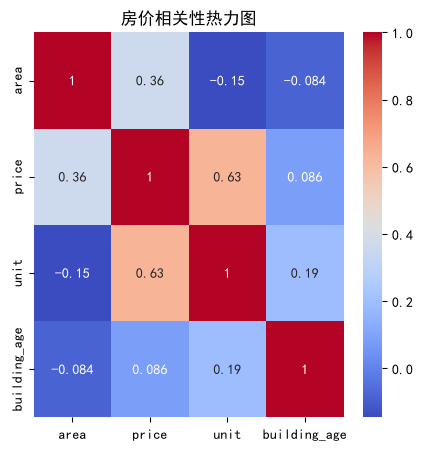

In [85]:
#2.绘制相关性热力图
plt.figure(figsize=(5,5)) #设置画布大小
sns.heatmap(relate,annot=True,cmap="coolwarm") #绘制热力图，annot=True:显示数值 cmap="coolwarm"：颜色为冷暖对比色
plt.title("房价相关性热力图")
plt.show()

###### 2.房价在全国不同地区的分布情况
###### 平均数、中位数、标准差

In [87]:
display(df.describe())

,area,price,unit,year,livingrooms_num,building_age
count,26499.000000,2.649900e+04,26499.000000,26499.000000,26499.000000,26499.000000
mean,103.951172,1.045302e+06,11661.091626,2013.095022,1.849428,12.904978
std,34.254848,7.132695e+05,5953.417974,6.006597,0.406808,6.006597
min,21.000000,9.200000e+00,1000.000000,1976.000000,0.000000,3.000000
25%,85.495000,5.900000e+05,7580.000000,2011.000000,2.000000,9.000000
50%,100.000000,9.700000e+05,10313.000000,2015.000000,2.000000,11.000000
75%,123.000000,1.450000e+06,14211.000000,2017.000000,2.000000,15.000000
max,470.000000,3.090000e+06,85288.000000,2023.000000,12.000000,50.000000


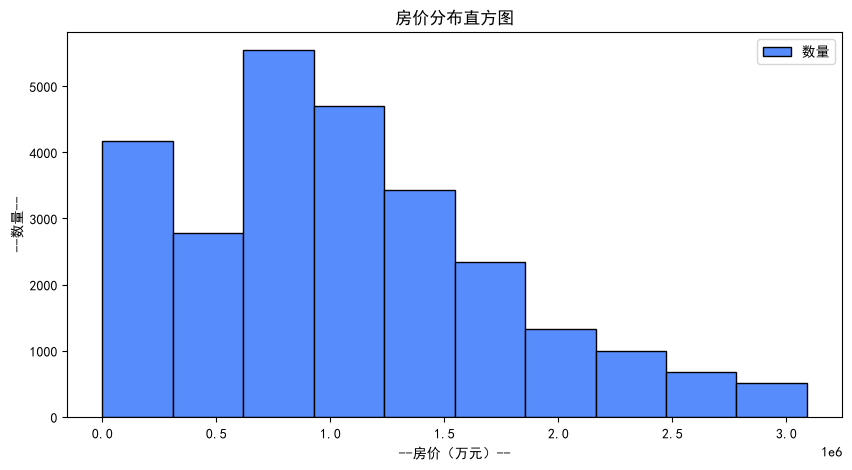

In [100]:
#房价分布的直方图   sns.histplot(列名,bins=5)
plt.figure(figsize=(10,5))
plt.hist(df["price"],bins=10,edgecolor="black",label="数量") #bins:分成多少个箱子
plt.title("房价分布直方图")
plt.xlabel('--房价（万元）--')
plt.ylabel('--数量--')
plt.legend(loc='upper right')
plt.show()

#### 3.房价在不同朝向的分布情况

In [105]:
display(df["toward"].value_counts().to_frame())
#方法一：按照朝向分组，计算每个组的平均房价观察
#按照朝向分组，计算每个组的平均房价
groupby_toward=df.groupby("toward").agg({
        "price":["mean","median"],
         "unit":["median"],
    "building_age":["mean"]
     }
)
display(groupby_toward)


,count
toward,
南北向,15064
南向,8962
东南向,979
东向,422
北向,258
西南向,256
西向,162
东西向,155
西北向,134


price                unit building_age
                mean     median   median         mean
toward                                               
东北向     1.112250e+06  1000000.0  12198.0    13.747664
东南向     1.003550e+06   980000.0  10866.0    11.949949
东向      9.660796e+05   860000.0  11421.0    13.725118
东西向     8.184032e+05   790000.0   8936.0    16.419355
北向      7.813322e+05   705000.0  11698.0    14.108527
南北向     1.071886e+06   980000.0  10000.0    13.062799
南向      1.014390e+06   950000.0  10764.0    12.508257
西北向     1.088219e+06  1050000.0  12290.0    14.417910
西南向     1.280089e+06  1290000.0  13333.0    14.414062
西向      9.287748e+05   820000.0  12514.0    14.339506

<Axes: xlabel='toward', ylabel='price'>

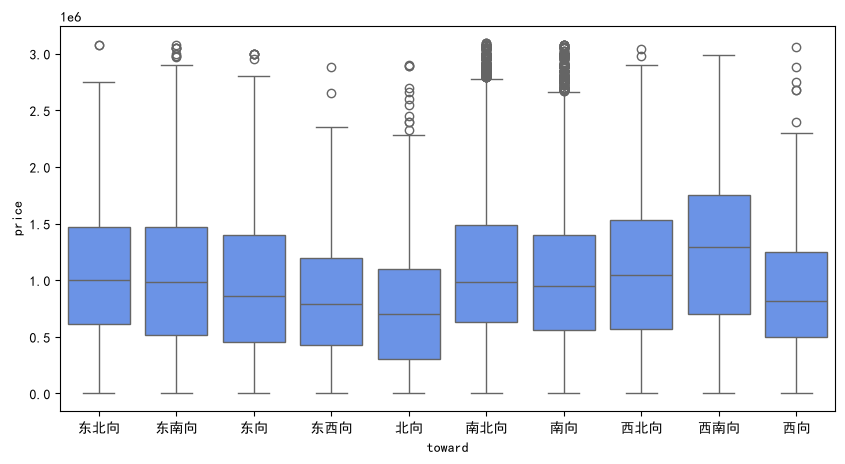

In [106]:
#方法二：数据可视化，绘制箱线图
plt.figure(figsize=(10,5))
sns.boxplot(x="toward",y="price",data=df) #使用sns绘制箱线图 朝向和房价的关系